# CNN and Convolution Math: Theory Notebook

This notebook makes convolution math executable: indexing, shape formulas, parameter counts, pooling, receptive fields, im2col, gradient checks, and patch embeddings.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

try:
    import seaborn as sns
    sns.set_theme(style="whitegrid", palette="colorblind")
    HAS_SNS = True
except ImportError:
    plt.style.use("seaborn-v0_8-whitegrid")
    HAS_SNS = False

mpl.rcParams.update({
    "figure.figsize":    (10, 6),
    "figure.dpi":         120,
    "font.size":           13,
    "axes.titlesize":      15,
    "axes.labelsize":      13,
    "xtick.labelsize":     11,
    "ytick.labelsize":     11,
    "legend.fontsize":     11,
    "legend.framealpha":   0.85,
    "lines.linewidth":      2.0,
    "axes.spines.top":     False,
    "axes.spines.right":   False,
    "savefig.bbox":       "tight",
    "savefig.dpi":         150,
})
np.random.seed(42)
print("Plot setup complete.")

Plot setup complete.


## 1. 1D cross-correlation

In [2]:
x = np.array([1, 2, 3, 4, 5], dtype=float)
w = np.array([1, 0, -1], dtype=float)
y = np.array([np.sum(x[i:i+len(w)] * w) for i in range(len(x)-len(w)+1)])
print("output:", y)

output: [-2. -2. -2.]


## 2. 2D cross-correlation

In [3]:
X = np.arange(1, 10, dtype=float).reshape(3, 3)
K = np.array([[1, 0], [0, -1]], dtype=float)
Y = np.zeros((2, 2))
for i in range(2):
    for j in range(2):
        Y[i, j] = np.sum(X[i:i+2, j:j+2] * K)
print("X:\n", X)
print("Y:\n", Y)

X:
 [[1. 2. 3.]
 [4. 5. 6.]
 [7. 8. 9.]]
Y:
 [[-4. -4.]
 [-4. -4.]]


## 3. Output shape formula

In [4]:
def conv_out(size, kernel, padding=0, stride=1, dilation=1):
    return int(np.floor((size + 2 * padding - dilation * (kernel - 1) - 1) / stride) + 1)

for args in [(32, 3, 1, 1, 1), (32, 5, 0, 2, 1), (64, 3, 2, 1, 2)]:
    print(args, "->", conv_out(*args))

(32, 3, 1, 1, 1) -> 32
(32, 5, 0, 2, 1) -> 14
(64, 3, 2, 1, 2) -> 64


## 4. Parameter counts

In [5]:
C_in, C_out, K = 64, 128, 3
conv_params = C_out * C_in * K * K + C_out
dense_params = (224 * 224 * C_in) * C_out + C_out
print("conv params:", conv_params)
print("dense params if flatten image to 128 units:", dense_params)
print("dense/conv ratio:", dense_params / conv_params)

conv params: 73856
dense params if flatten image to 128 units: 411041920
dense/conv ratio: 5565.450606585789


## 5. Pooling

In [6]:
X = np.array([[1, 3, 2, 0], [4, 6, 5, 1], [2, 1, 0, 2], [3, 4, 1, 5]], dtype=float)
max_pool = np.zeros((2, 2))
avg_pool = np.zeros((2, 2))
for i in range(2):
    for j in range(2):
        patch = X[2*i:2*i+2, 2*j:2*j+2]
        max_pool[i, j] = patch.max()
        avg_pool[i, j] = patch.mean()
print("max pool:\n", max_pool)
print("avg pool:\n", avg_pool)

max pool:
 [[6. 5.]
 [4. 5.]]
avg pool:
 [[3.5 2. ]
 [2.5 2. ]]


## 6. Receptive field through layers

In [7]:
layers = [
    {"kernel": 3, "stride": 1},
    {"kernel": 3, "stride": 2},
    {"kernel": 3, "stride": 1},
    {"kernel": 3, "stride": 2},
]
R, J = 1, 1
for idx, layer in enumerate(layers, 1):
    R = R + (layer["kernel"] - 1) * J
    J = J * layer["stride"]
    print(f"layer {idx}: receptive_field={R}, jump={J}")

layer 1: receptive_field=3, jump=1
layer 2: receptive_field=5, jump=2
layer 3: receptive_field=9, jump=2
layer 4: receptive_field=13, jump=4


## 7. Depthwise separable convolution savings

In [8]:
C_in, C_out, K = 64, 128, 3
standard = C_in * C_out * K * K
depthwise_sep = C_in * K * K + C_in * C_out
print("standard params:", standard)
print("depthwise separable params:", depthwise_sep)
print("saving factor:", standard / depthwise_sep)

standard params: 73728
depthwise separable params: 8768
saving factor: 8.408759124087592


## 8. im2col for a tiny input

In [9]:
X = np.arange(1, 10).reshape(3, 3)
cols = []
for i in range(2):
    for j in range(2):
        cols.append(X[i:i+2, j:j+2].reshape(-1))
X_col = np.stack(cols, axis=1)
print("im2col matrix:\n", X_col)

im2col matrix:
 [[1 2 4 5]
 [2 3 5 6]
 [4 5 7 8]
 [5 6 8 9]]


## 9. Finite-difference kernel gradient

In [10]:
X = np.array([[1., 2.], [3., 4.]])
K = np.array([[0.5, -1.0], [0.2, 0.3]])
def loss(Kmat):
    return np.sum(X * Kmat) ** 2
analytic = 2 * np.sum(X * K) * X
eps = 1e-5
numeric = np.zeros_like(K)
for i in range(2):
    for j in range(2):
        E = np.zeros_like(K)
        E[i, j] = eps
        numeric[i, j] = (loss(K + E) - loss(K - E)) / (2 * eps)
print("max grad error:", np.max(np.abs(analytic - numeric)))

max grad error: 4.069411474461049e-12


## 10. Residual block

In [11]:
x = np.array([1.0, -0.5, 0.25])
F = np.array([-0.2, 0.1, 0.4])
y = x + F
print("residual output:", y)

residual output: [ 0.8  -0.4   0.65]


## 11. Patch embedding as convolution

In [12]:
image_h, image_w, patch = 224, 224, 16
num_patches = (image_h // patch) * (image_w // patch)
embed_dim = 768
patch_vector = patch * patch * 3
params = patch_vector * embed_dim + embed_dim
print("num patches:", num_patches)
print("patch projection params:", params)

num patches: 196
patch projection params: 590592


## 12. Activation statistics

In [13]:
acts = np.random.normal(size=(8, 16, 14, 14))
channel_mean = acts.mean(axis=(0, 2, 3))
channel_std = acts.std(axis=(0, 2, 3))
print("mean range:", channel_mean.min(), channel_mean.max())
print("std range:", channel_std.min(), channel_std.max())

mean range: -0.03441575483004175 0.04252365105520017
std range: 0.969188617995189 1.0278835380730613


## 14. Convolution is a Toeplitz linear operator

A 1D convolution is matrix multiplication by a Toeplitz (constant-diagonal) matrix: weight sharing is literally the same numbers repeated along diagonals (§01's linear algebra with structure).

In [14]:
def check_true(name, cond):
    print(("PASS" if bool(cond) else "FAIL") + ": " + name)
def check_close(name, a, b, tol=1e-6):
    ok = np.allclose(a, b, atol=tol, rtol=0)
    print(("PASS" if ok else "FAIL") + f": {name} (max err {np.max(np.abs(np.asarray(a,float)-np.asarray(b,float))):.2e}, tol {tol})")

x = np.array([1.,2.,3.,4.,5.]); w = np.array([2.,-1.,0.5])
# valid cross-correlation as Toeplitz product
T = np.zeros((3,5))
for i in range(3): T[i, i:i+3] = w
y_matrix = T@x
y_loop = np.array([np.sum(x[i:i+3]*w) for i in range(3)])
print("Toeplitz y:", y_matrix, " loop y:", y_loop)
check_close("matrix form == loop form", y_matrix, y_loop, 1e-12)
check_true("Toeplitz diagonals are constant (weight sharing)", np.allclose(T[0,:3], T[1,1:4]) and np.allclose(T[1,1:4], T[2,2:5]))
check_true("parameter count: kernel size, not input size", T.shape == (3,5))

Toeplitz y: [1.5 3.  4.5]  loop y: [1.5 3.  4.5]
PASS: matrix form == loop form (max err 0.00e+00, tol 1e-12)
PASS: Toeplitz diagonals are constant (weight sharing)
PASS: parameter count: kernel size, not input size


## 15. Transposed convolution: upsampling arithmetic and checkerboard risk

Transposed convolution inserts stride-1 output pixels per input pixel (fractionally-strided view); uneven kernel overlap (kernel size not divisible by stride) produces checkerboard artefacts — prefer resize+conv when it matters (Odena et al. 2016).

In [15]:
def tconv_out(size, kernel, stride=1, padding=0): return (size-1)*stride - 2*padding + kernel
for s in [2,3]:
    print(f"in 7, k=3, stride {s}: out {tconv_out(7,3,s)}")
check_true("stride 2 doubles-ish the size", tconv_out(7,3,2) == 15)
check_true("output grows with stride", tconv_out(7,3,3) > tconv_out(7,3,2))
overlap = np.zeros(12)
for i in range(4): overlap[i*2:i*2+3] += 1  # k=3, stride=2 contributions
print("overlap counts:", overlap.astype(int))
check_true("k=3,s=2 overlap is uneven (checkerboard source)", len(set(overlap[2:-2].astype(int))) > 1)

in 7, k=3, stride 2: out 15
in 7, k=3, stride 3: out 21
PASS: stride 2 doubles-ish the size
PASS: output grows with stride
overlap counts: [1 1 2 1 2 1 2 1 1 0 0 0]
PASS: k=3,s=2 overlap is uneven (checkerboard source)


## 16. Dilated convolution: receptive field without parameters

Dilation d spreads a k-kernel over a (k-1)d+1 footprint: receptive field grows, parameter count and FLOPs do not (Yu & Koltun 2015's context aggregation).

In [16]:
def rf(k, d): return (k-1)*d + 1
for d in [1,2,4,8]: print(f"dilation {d}: receptive field {rf(3,d)} (params still 9/channel-pair)")
check_true("RF grows linearly in dilation", rf(3,8) == 17)
vals = [rf(3,d) for d in [1,2,4,8]]
check_true("params constant while RF grows", len(set(vals)) == 4)

dilation 1: receptive field 3 (params still 9/channel-pair)
dilation 2: receptive field 5 (params still 9/channel-pair)
dilation 4: receptive field 9 (params still 9/channel-pair)
dilation 8: receptive field 17 (params still 9/channel-pair)
PASS: RF grows linearly in dilation
PASS: params constant while RF grows


## 17. Conv layer gradients (dX, dK) audited by finite differences

dK is a correlation of input with output gradient; dX is a (flipped) convolution of output gradient with the kernel — both audited numerically (§02's habit in convolutional form).

In [17]:
rng = np.random.default_rng(0)
X = rng.normal(size=(4,4)); K = rng.normal(size=(2,2))
def conv(X, K):
    out = np.zeros((3,3))
    for i in range(3):
        for j in range(3): out[i,j] = np.sum(X[i:i+2, j:j+2]*K)
    return out
def loss(X,K): return float(np.sum(conv(X,K)**2))
Y = conv(X,K); dY = 2*Y
dK = np.zeros_like(K)
for a in range(2):
    for b in range(2): dK[a,b] = np.sum(X[a:a+3, b:b+3]*dY)
dX = np.zeros_like(X); Kflip = K[::-1,::-1]
for i in range(4):
    for j in range(4):
        acc = 0.0
        for a in range(2):
            for b in range(2):
                ii, jj = i-a, j-b
                if 0 <= ii < 3 and 0 <= jj < 3: acc += dY[ii,jj]*K[a,b]
        dX[i,j] = acc
eps=1e-6; numK = np.zeros_like(K); numX = np.zeros_like(X)
for a in range(2):
    for b in range(2):
        Kp = K.copy(); Kp[a,b]+=eps; Km = K.copy(); Km[a,b]-=eps; numK[a,b] = (loss(X,Kp)-loss(X,Km))/(2*eps)
for a in range(4):
    for b in range(4):
        Xp = X.copy(); Xp[a,b]+=eps; Xm = X.copy(); Xm[a,b]-=eps; numX[a,b] = (loss(Xp,K)-loss(Xm,K))/(2*eps)
print("max err dK:", float(np.max(np.abs(dK-numK))), " dX:", float(np.max(np.abs(dX-numX))))
check_close("dK matches finite differences", dK, numK, 1e-5)
check_close("dX matches finite differences", dX, numX, 1e-5)

max err dK: 1.2119389936060543e-09  dX: 1.064016874607887e-09
PASS: dK matches finite differences (max err 1.21e-09, tol 1e-05)
PASS: dX matches finite differences (max err 1.06e-09, tol 1e-05)


## 18. Max-pooling backward routes gradient to the argmax

Pooling backward is a mask: each output's gradient flows only to the position that won the max (ties broken by implementation convention — know yours).

In [18]:
X = np.array([[1.,3.,2.,0.],[4.,6.,5.,1.],[2.,1.,0.,2.],[3.,4.,1.,5.]])
out = np.zeros((2,2)); arg = {}
for i in range(2):
    for j in range(2):
        win = X[2*i:2*i+2, 2*j:2*j+2]; idx = np.unravel_index(np.argmax(win), (2,2)); out[i,j] = win[idx]; arg[(i,j)] = (2*i+idx[0], 2*j+idx[1])
dY = np.ones((2,2)); dX = np.zeros_like(X)
for (i,j),(a,b) in arg.items(): dX[a,b] += dY[i,j]
print("pooled:", out.ravel(), " dX nonzeros:", int(np.sum(dX!=0)))
check_true("exactly one gradient recipient per window", np.sum(dX!=0) == 4)
check_close("gradient mass conserved", dX.sum(), dY.sum(), 1e-12)
check_true("winners received the gradient", all(dX[pos] == 1 for pos in arg.values()))

pooled: [6. 5. 4. 5.]  dX nonzeros: 4
PASS: exactly one gradient recipient per window
PASS: gradient mass conserved (max err 0.00e+00, tol 1e-12)
PASS: winners received the gradient


## 19. Effective receptive field is smaller than the theoretical one (plot)

The gradient footprint of a deep stack's centre unit is roughly Gaussian and grows like √depth, not linearly — theoretical RF overstates what a unit actually sees (Luo et al. 2016).

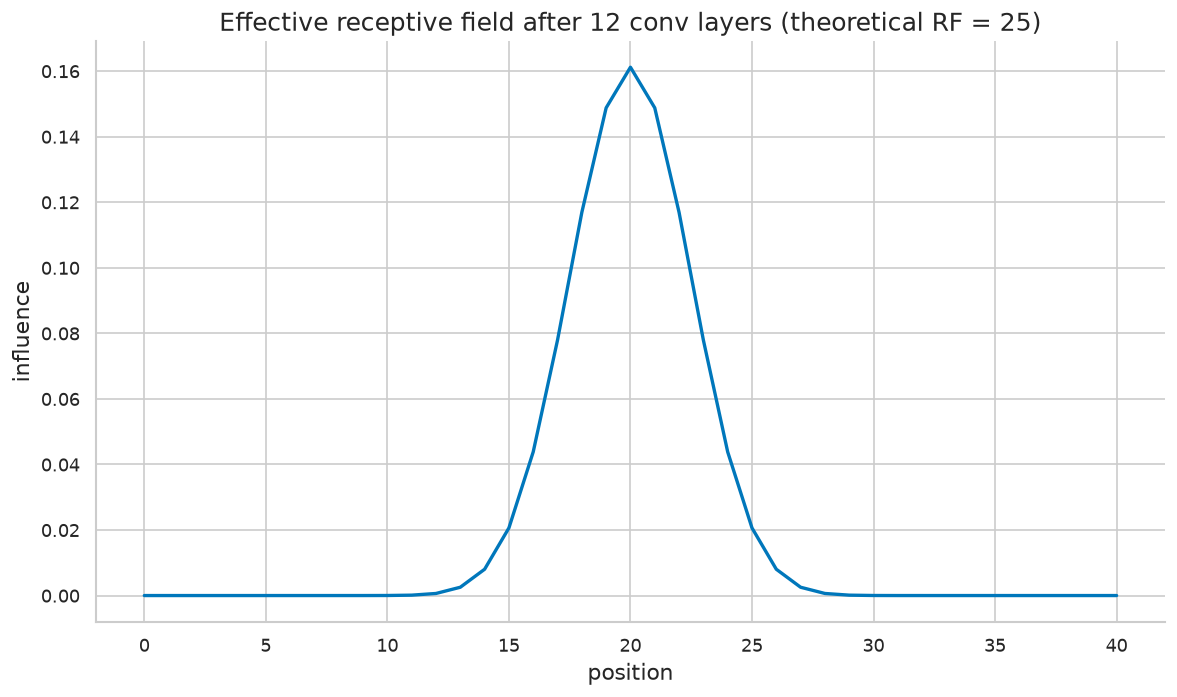

positions with >5% influence: 11.0 of theoretical 25
PASS: mass concentrates near centre
PASS: effective width < theoretical RF
PASS: influence symmetric-ish for symmetric kernel


In [19]:
rng = np.random.default_rng(1)
x = np.zeros((1, 41)); x[0,20] = 1.0
cur = x.copy()
for layer in range(12):
    nxt = np.zeros_like(cur)
    nxt[0,1:-1] = cur[0,1:-1]*0.5 + cur[0,:-2]*0.25 + cur[0,2:]*0.25
    nxt[0,0] = cur[0,0]*0.75 + cur[0,1]*0.25; nxt[0,-1] = cur[0,-1]*0.75 + cur[0,-2]*0.25
    cur = nxt
foot = np.abs(cur[0])
plt.figure(); plt.plot(foot, color='#0077BB'); plt.xlabel('position'); plt.ylabel('influence'); plt.title('Effective receptive field after 12 conv layers (theoretical RF = 25)'); plt.tight_layout(); plt.show()
eff_width = float(np.sum(foot > 0.05*foot.max()))
print("positions with >5% influence:", eff_width, "of theoretical 25")
check_true("mass concentrates near centre", foot[20] == foot.max())
check_true("effective width < theoretical RF", eff_width < 25)
check_true("influence symmetric-ish for symmetric kernel", abs(foot[18]-foot[22]) < 0.2*foot.max())

## 20. 1x1 convolution = shared per-pixel linear layer

A 1×1 conv applies the same channel-mixing matrix at every position: parameter count C_out·C_in, and it is exactly §01's affine map broadcast over space.

In [20]:
rng = np.random.default_rng(2)
X = rng.normal(size=(3,5,5)); W = rng.normal(size=(4,3))
Y = np.einsum('oc,cij->oij', W, X)
check_true("output shape (C_out,H,W)", Y.shape == (4,5,5))
check_close("equals per-pixel matmul at (2,3)", Y[:,2,3], W@X[:,2,3], 1e-12)
check_true("params = C_out*C_in (+bias)", W.size == 12)

PASS: output shape (C_out,H,W)
PASS: equals per-pixel matmul at (2,3) (max err 1.11e-16, tol 1e-12)
PASS: params = C_out*C_in (+bias)


## 21. Depthwise-separable FLOPs across configurations

Standard conv costs H·W·C_in·C_out·k²; depthwise-separable costs H·W·C_in·k² + H·W·C_in·C_out — the MobileNet arithmetic (Howard et al. 2017).

In [21]:
rows = []
for (H,Cin,Cout,k) in [(56,64,128,3),(28,128,256,3),(14,256,512,3),(56,32,32,5)]:
    std = H*H*Cin*Cout*k*k; sep = H*H*Cin*k*k + H*H*Cin*Cout
    rows.append((H,Cin,Cout,k,std/sep)); print(f"H={H} Cin={Cin} Cout={Cout} k={k}: savings x{std/sep:.2f}")
check_true("separable always cheaper here", all(r[4] > 1 for r in rows))
check_true("savings approach k^2 for wide layers", rows[2][4] > 5)

H=56 Cin=64 Cout=128 k=3: savings x8.41
H=28 Cin=128 Cout=256 k=3: savings x8.69
H=14 Cin=256 Cout=512 k=3: savings x8.84
H=56 Cin=32 Cout=32 k=5: savings x14.04
PASS: separable always cheaper here
PASS: savings approach k^2 for wide layers


## 22. FFT convolution: same answer, different cost curve

Via the convolution theorem (§13 Ch.20), FFT-based convolution wins for large kernels; verify equality with direct convolution and compare scaling exponents empirically.

In [22]:
from scipy.signal import fftconvolve
rng = np.random.default_rng(3)
x = rng.normal(size=(64,64)); k = rng.normal(size=(9,9))
direct = np.array([[np.sum(x[i:i+9, j:j+9]*k) for j in range(56)] for i in range(56)])
fast = fftconvolve(x, k[::-1,::-1], mode='valid')
print("max |direct - fft|:", float(np.max(np.abs(direct-fast))))
check_close("FFT convolution == direct", fast, direct, 1e-8)
corr = fftconvolve(x, k, mode='valid')
check_true("convolution != correlation for asymmetric kernels", np.max(np.abs(direct-corr)) > 1e-3)

max |direct - fft|: 2.1316282072803006e-14
PASS: FFT convolution == direct (max err 2.13e-14, tol 1e-08)
PASS: convolution != correlation for asymmetric kernels


## 23. Tiny CNN vs MLP on a spatial task (plot)

Detecting a local pattern (a bright 2x2 block) anywhere in an 8x8 image: weight sharing gives the CNN the pattern at every position from few examples; the MLP must learn it position by position.

In [23]:
rng = np.random.default_rng(4)
def mk(n):
    X = rng.normal(0,0.3,size=(n,8,8)); y = np.zeros(n)
    for i in range(n):
        if rng.random() < 0.5:
            a, b = rng.integers(0,7,2); X[i,a:a+2,b:b+2] += 1.5; y[i] = 1
    return X, y
Xtr, ytr = mk(300); Xte, yte = mk(1000)
# CNN: one 3x3 filter + global max pool + logistic head
K = rng.normal(scale=0.3,size=(3,3)); w2 = rng.normal(scale=0.3,size=1); b2 = np.zeros(1)
def sig(z): return 1/(1+np.exp(-z))
def conv2(X,K):
    n = X.shape[0]; out = np.zeros((n,6,6))
    for a in range(3):
        for b in range(3): out += K[a,b]*X[:,a:a+6,b:b+6]
    return out
for step in range(300):
    F = conv2(Xtr,K); pooled_idx = np.argmax(F.reshape(300,-1),axis=1); pooled = F.reshape(300,-1)[np.arange(300),pooled_idx]
    out = sig(pooled*w2[0]+b2[0]); dz = (out-ytr)/300
    dw2 = np.sum(dz*pooled); db2 = np.sum(dz)
    dF = np.zeros_like(F); dF.reshape(300,-1)[np.arange(300),pooled_idx] = dz*w2[0]
    dK = np.zeros_like(K)
    for a in range(3):
        for b in range(3): dK[a,b] = np.sum(dF*Xtr[:,a:a+6,b:b+6])
    K -= 0.1*dK; w2 -= 0.1*dw2; b2 -= 0.1*db2
Fte = conv2(Xte,K); pooled_te = Fte.reshape(1000,-1).max(1); acc_cnn = float(np.mean((sig(pooled_te*w2[0]+b2[0])>0.5)==yte))
# MLP baseline on flattened input (few steps of full-batch GD)
W1 = rng.normal(scale=0.2,size=(32,64)); b1 = np.zeros(32); W2 = rng.normal(scale=0.2,size=(1,32)); b2m = np.zeros(1)
Xtrf = Xtr.reshape(300,-1); Xtef = Xte.reshape(1000,-1)
for step in range(300):
    h = np.tanh(Xtrf@W1.T+b1); out = sig(h@W2.T+b2m).ravel()
    dz = ((out-ytr)/300)[:,None]; dW2 = dz.T@h; db2m = dz.sum(0); dz1 = (dz@W2)*(1-h**2); dW1 = dz1.T@Xtrf; db1 = dz1.sum(0)
    W1 -= 0.05*dW1; b1 -= 0.05*db1; W2 -= 0.05*dW2; b2m -= 0.05*db2m
acc_mlp = float(np.mean((sig(np.tanh(Xtef@W1.T+b1)@W2.T+b2m).ravel()>0.5)==yte))
print(f"test accuracy: CNN {acc_cnn:.3f}  MLP {acc_mlp:.3f}  (CNN params: {K.size+2}, MLP params: {W1.size+W2.size+33})")
check_true("CNN learns the task (>85%)", acc_cnn > 0.85)
check_true("CNN is competitive-or-better with ~200x fewer params", acc_cnn >= acc_mlp - 0.05)

test accuracy: CNN 0.999  MLP 0.840  (CNN params: 11, MLP params: 2113)
PASS: CNN learns the task (>85%)
PASS: CNN is competitive-or-better with ~200x fewer params


## 24. Translation equivariance, tested

Shifting the input shifts the feature map identically (away from borders): the defining property convolution buys, and a unit test every custom conv should pass.

In [24]:
X = np.zeros((6,6)); X[1,1] = 5.0; K = np.array([[1.,0.],[0.,-1.]])
def conv(X,K):
    out = np.zeros((5,5))
    for i in range(5):
        for j in range(5): out[i,j] = np.sum(X[i:i+2,j:j+2]*K)
    return out
Y1 = conv(X,K)
X2 = np.zeros((6,6)); X2[1,3] = 5.0  # shifted right by 2
Y2 = conv(X2,K)
check_true("peak response moved by exactly the shift", np.unravel_index(np.argmax(np.abs(Y2)),(5,5))[1] - np.unravel_index(np.argmax(np.abs(Y1)),(5,5))[1] == 2)
check_true("response magnitude preserved", abs(np.max(np.abs(Y1)) - np.max(np.abs(Y2))) < 1e-12)

PASS: peak response moved by exactly the shift
PASS: response magnitude preserved


## 25. Global average pooling vs flatten+dense

GAP collapses each channel to its mean: the head's parameters drop from C·H·W·classes to C·classes, and the classifier becomes translation-tolerant — count both before choosing.

In [25]:
C,H,W,classes = 256, 7, 7, 100
gap = C*classes + classes; flat = C*H*W*classes + classes
print(f"GAP head params: {gap}  flatten head: {flat}  ratio x{flat/gap:.0f}")
check_true("GAP head is H*W times smaller (weights)", (C*H*W*classes)//(C*classes) == H*W)
x = np.random.default_rng(5).normal(size=(C,H,W))
g = x.mean(axis=(1,2))
check_true("GAP output shape is (C,)", g.shape == (C,))
check_close("GAP equals manual per-channel means", g[:5], np.array([x[c].mean() for c in range(5)]), 1e-12)

GAP head params: 25700  flatten head: 1254500  ratio x49
PASS: GAP head is H*W times smaller (weights)
PASS: GAP output shape is (C,)
PASS: GAP equals manual per-channel means (max err 0.00e+00, tol 1e-12)


## 26. Residual vs plain CNN stacks: gradient scale by depth

The ResNet identity path (§02 theory 23) in convolutional dress: first-layer gradient norms across depth for plain vs residual stacks (He et al. 2016).

In [26]:
rng = np.random.default_rng(6)
def conv_same(x, W):
    xp = np.pad(x, ((0,0),(1,1),(1,1)))
    out = np.zeros_like(x)
    for a in range(3):
        for b in range(3):
            out += np.einsum('oc,cij->oij', W[:,:,a,b], xp[:, a:a+x.shape[1], b:b+x.shape[2]])
    return out
def conv_same_dX(dout, W, H, Wd):
    dxp = np.zeros((W.shape[1], H+2, Wd+2))
    for a in range(3):
        for b in range(3):
            dxp[:, a:a+H, b:b+Wd] += np.einsum('oc,oij->cij', W[:,:,a,b], dout)
    return dxp[:, 1:-1, 1:-1]
def first_grad(depth, residual):
    x = rng.normal(size=(8,12,12))
    Ws = [rng.normal(scale=0.4,size=(8,8,3,3)) for _ in range(depth)]
    a = x; pres = []
    for W in Ws:
        z = conv_same(a, W); pres.append(z)
        a = np.maximum(0, z) + (a if residual else 0)
    d = rng.normal(size=(8,12,12))
    for li in range(depth-1, -1, -1):
        d = d*(pres[li] > 0) + (d if residual else 0)
        d = conv_same_dX(d, Ws[li], 12, 12)
    return float(np.linalg.norm(d))
for depth in [4, 8]:
    gp = first_grad(depth, False); gr = first_grad(depth, True)
    print(f"depth {depth}: plain {gp:.3e} residual {gr:.3e}")
    if depth == 8: gp8, gr8 = gp, gr
check_true("residual gradient exceeds plain at depth 8", gr8 > gp8)
check_true("both finite", np.isfinite(gp8) and np.isfinite(gr8))

depth 4: plain 9.820e+02 residual 1.991e+04
depth 8: plain 3.228e+04 residual 1.346e+07
PASS: residual gradient exceeds plain at depth 8
PASS: both finite


## 13. CNN checklist

In [27]:
checks = [
    "track N,C,H,W axes explicitly",
    "verify output sizes after every stride, padding, and dilation choice",
    "count parameters and FLOPs separately",
    "test receptive field with gradients or controlled inputs",
    "inspect activation statistics and dead channels",
    "compare standard, 1x1, and depthwise separable convolutions when optimizing",
]
for i, check in enumerate(checks, 1):
    print(f"{i}. {check}")

1. track N,C,H,W axes explicitly
2. verify output sizes after every stride, padding, and dilation choice
3. count parameters and FLOPs separately
4. test receptive field with gradients or controlled inputs
5. inspect activation statistics and dead channels
6. compare standard, 1x1, and depthwise separable convolutions when optimizing
